# Secure Grid Backbone: one working link

*Secure the Grid, step 3 · UTC Problem 6*

The capstone is mostly a design (do the design in your write-up). This notebook is just the **one working link** you need for Part 3.

Pick ONE:
- **Option A:** reuse your BB84 notebook from Step 1 (`1_bb84_eavesdropper.ipynb`) as the link, or
- **Option B:** build the quantum teleportation circuit below (sending one key qubit between nodes).

On a real link, the entangled pair is delivered over fiber, and the two corrections travel as two ordinary classical bits. Here all three qubits are on one chip, so this shows the logic of the link, not its distance. If you pick Option B, say in your write-up how a link like this could change the trusted-node problem in Part 1.

> **Before you run anything, pick the kernel.** When this notebook opens, a **Select Kernel** box appears with *Python 3 (ipykernel)* already selected. That's the wrong one: change it to **qBraid-SDK (v0.12.2)**, then click **Select**. Picked the wrong one, or closed the box? Click the kernel name at the top right of the notebook and choose **qBraid-SDK (v0.12.2)**. The first cell checks, and tells you if it's wrong.

In [1]:
# Use the qBraid-SDK (v0.12.2) kernel. This stops with a clear message if another one is picked.
import importlib.util
missing = [m for m in ("qbraid", "matplotlib") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError("Wrong kernel: this one has no " + " or ".join(missing) + ". Click the kernel name "
                      "at the top right of the notebook, pick qBraid-SDK (v0.12.2), then run this cell again.")

# Qiskit Aer is Qiskit's simulator. It runs right here in your Lab instance: instant, free and noise-free,
# with no job and no credits. The first run installs it (a few seconds), pinned to the version tested here.
try:
    import qiskit_aer  # noqa: F401
except ImportError:
    %pip install -q qiskit-aer==0.18.2

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
sim = AerSimulator()

print("Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.")

Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.


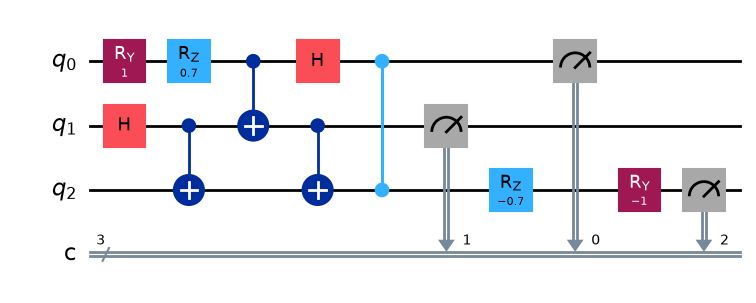

In [2]:
def teleport_circuit():
    """Teleport the state of qubit 0 to qubit 2 using an entangled pair (1,2)."""
    qc = QuantumCircuit(3, 3)
    # Prepare a state to send on qubit 0.
    qc.ry(1.0, 0)
    qc.rz(0.7, 0)

    # Entangle qubits 1 and 2. On a real link this pair is shared over fiber.
    qc.h(1)
    qc.cx(1, 2)

    # Alice links her message qubit (0) to her half of the pair (1).
    qc.cx(0, 1)
    qc.h(0)

    # Corrections on Bob's qubit (2), written as plain gates (deferred measurement).
    qc.cx(1, 2)
    qc.cz(0, 2)

    # Undo the state we sent. If the link worked, qubit 2 is back to 0.
    qc.rz(-0.7, 2)
    qc.ry(-1.0, 2)

    # Measure all three qubits at the end.
    qc.measure([0, 1, 2], [0, 1, 2])
    return qc

qc = teleport_circuit()
qc.draw("mpl")


In [3]:
# Run and show it works
counts = sim.run(transpile(qc, sim), shots=1024).result().get_counts()
print(counts)

# Qiskit prints bits as (qubit 2)(qubit 1)(qubit 0). Qubits 0 and 1 are random.
# Undoing the state you sent turns qubit 2 back into |0>, so if the link works, it reads 0 on every shot.
measured_q2 = any(i.operation.name == "measure" and qc.find_bit(i.qubits[0]).index == 2 for i in qc.data)
if not measured_q2:
    print("Qubit 2 is not measured yet: undo the state on qubit 2, then measure it (see the hint).")
else:
    zeros = sum(c for bits, c in counts.items() if bits[0] == "0")
    print(f"qubit 2 read 0 on {zeros} of {sum(counts.values())} shots (all of them means the link works)")


{'011': 242, '010': 279, '000': 257, '001': 246}
qubit 2 read 0 on 1024 of 1024 shots (all of them means the link works)


In [4]:
# Run the same link through qBraid on IonQ's free simulator
from qbraid.runtime import QbraidProvider
import warnings
warnings.filterwarnings("ignore", message="Circuit contains measurement gates")  # IonQ measures every qubit anyway

device = QbraidProvider().get_device("ionq:ionq:sim:simulator")
job = device.run(qc, shots=200, runtime_options={"noise_model": "forte-1"})
print("Job ID:", job.id)          # copy this into your write-up
ionq_counts = job.result().data.get_counts()
zeros = sum(c for bits, c in ionq_counts.items() if bits[0] == "0")
print(f"qubit 2 read 0 on {zeros} of {sum(ionq_counts.values())} shots (close to all means the link works)")
# qBraid may warn that measurements are ignored: IonQ measures every qubit at the end, and the
# cx/cz corrections still work because they are applied as quantum gates.


Job ID: ionq:ionq:sim:simulator-b095-qjob-6af89604c8f5265fb3f1cbf3
qubit 2 read 0 on 195 of 200 shots (close to all means the link works)


## What to have ready
Written answers go in `WRITEUP.md` in this folder.
- **Part 3:** this notebook (or your reused BB84) running, with a result.
- **Parts 1, 2, 4 and 5:** the architecture, assumptions and tradeoffs, rollout plan, and cost-versus-security argument, in your write-up. Save your network diagram as an image in this folder: it's your Solution slide.
- **For your deck:** see Step 4 in the track README.
